<a href="https://colab.research.google.com/github/anayamgreen/A05-pca/blob/main/A5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Anaya Green

**Date:** 10/21/2026

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [44]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
#Counter(token_freq).most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

One thing I noticed about this histogram is that there is a big right skew. Most of the tokens have a lower frequency of occurrence, while only a few tokens occur very frequently.

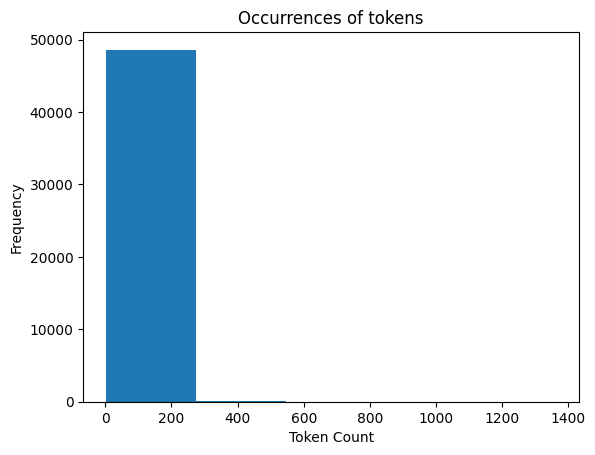

In [45]:
# Load in packages
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# make hist
plt.hist(token_count.values(), bins=5)
#make title for hist
plt.title("Occurrences of tokens")
# make an xlabel for the hist
plt.xlabel("Token Count")
#make a ylabel for the hist
plt.ylabel("Frequency")
# show plot
plt.show()

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?

Training R-squared: 0.7678
Test R-squared: 0.6571

3. What words have the largest coefficients in absolute value and most strongly influence predictions?

The words with the largest coefficients in absolute value were aging, helvetica, localized, background image, and thermal. Aging had the largest coefficient at about 0.997, meaning it had the strongest influence on the predictions.

In [46]:
#load oackages
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


from sklearn.linear_model import LinearRegression

#load in data
df = pd.read_parquet("Phishing_clean.parquet")

#look at data and columns
print(df.head())
print(df.columns.to_numpy())

#seperate x and y variables
eval_X_raw = df.drop(columns=["Email Type"])
eval_y = df["Email Type"]

#80/20 train test split
(
    eval_X_train_raw,
    eval_X_valid_raw,
    eval_y_train,
    eval_y_valid,
) = train_test_split(
    eval_X_raw, eval_y, test_size=0.20, random_state=65
)

#scale the data
eval_scaler = MinMaxScaler()
eval_X_train_scaled = eval_scaler.fit_transform(eval_X_train_raw)
eval_X_valid_scaled = eval_scaler.transform(eval_X_valid_raw)


#multiple linear regression
def mlr(X, y):
    #find coefficients
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    #predicted y values
    y_hat = X @ b

    #find residuals
    residuals = y - y_hat

    #calculate SSE
    sse = np.inner(residuals, residuals)

    #calculate R-squared
    rsq = 1 - sse / np.inner(y - np.mean(y), y - np.mean(y))

    #return regression results
    return {"b": b, "y_hat": y_hat, "residuals": residuals,
            "rsq": rsq, "SSE": sse}


#add intercept
eval_X_train_raw = eval_X_train_raw.copy()
eval_X_valid_raw = eval_X_valid_raw.copy()

#intercept equals 1
eval_X_train_raw["(Intercept)"] = 1
eval_X_valid_raw["(Intercept)"] = 1
#put intercept first
cols = ["(Intercept)"] + [
    col for col in eval_X_train_raw.columns
    if col != "(Intercept)"
]

#reorder colums
eval_X_train_raw = eval_X_train_raw[cols]
eval_X_valid_raw = eval_X_valid_raw[cols]


#fit regression for training data
fit = mlr(eval_X_train_raw, eval_y_train)

#training r-squared
print("Training R-squared:", round(fit["rsq"], 4))


#use training coefficients to predict test data
eval_y_hat_valid = eval_X_valid_raw @ fit["b"]

#test residuals
eval_valid_residuals = eval_y_valid - eval_y_hat_valid

#test SSE
eval_valid_sse = np.inner(
    eval_valid_residuals,
    eval_valid_residuals
)

#test r-squared
eval_valid_rsq = 1 - eval_valid_sse / np.inner(
    eval_y_valid - np.mean(eval_y_valid),
    eval_y_valid - np.mean(eval_y_valid)
)

#print test r-squared
print("Test R-squared:", round(eval_valid_rsq, 4))


#absolute value of coefficents
abs_b = np.abs(fit["b"])

#sort coefficients from largest to smallest
order = np.argsort(abs_b)[::-1]

#print words with largest coefficients
for i in order[:10]:
    print(eval_X_train_raw.columns[i], fit["b"][i])


   Email Type  new  date  get  please  enron  like  2002  would  one  ...  \
0           0    0     0    0       0      0     0     0      0    0  ...   
1           0    0     0    0       0      0     0     0      0    0  ...   
2           0    1     0    0       0      0     0     0      0    0  ...   
3           1    0     0    0       0      0     0     0      0    1  ...   
4           1    0     0    0       0      0     0     0      0    0  ...   

   ï¿½ï¿½  safety  yap  ypil  maintain  procedures  tip  elizabeth  \
0       0       0    0     0         0           0    0          0   
1       0       0    0     0         0           0    0          0   
2       0       0    0     0         0           0    0          0   
3       0       0    0     0         0           0    0          0   
4       0       0    0     0         0           0    0          0   

   leadership  italian  
0           0        0  
1           0        0  
2           0        0  
3           0   

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?



There is a lot of overlap between the phishing and non-phishing emails, so the first two principal components do not really separate them. There are a few smaller groups that are individualized, but both email types are still mixed together.

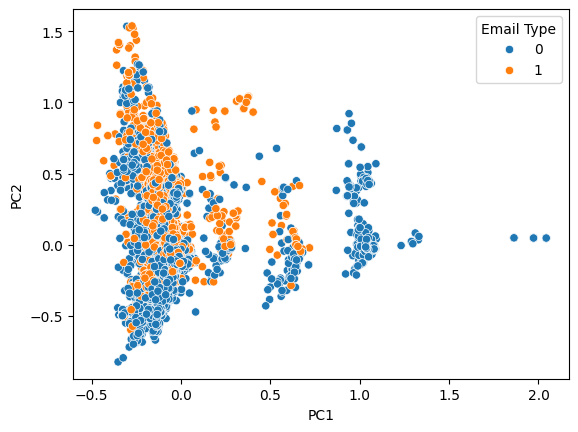

In [47]:

# less outcome variable
X_pca = df.drop(columns=["Email Type", "(Intercept)"], errors="ignore")

# center data
Z = X_pca - X_pca.mean()

# calculate covariance matrix
C = Z.T @ Z / (len(Z) - 1)

# find eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(C)

# aort from largest eigenvalue to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

#keep the first two principal components
P = eigenvectors[:, :2]

# transform the data
X_pca_2 = Z @ P

#Put the two components into a DataFrame for plotting
pca_df = pd.DataFrame({
    "PC1": X_pca_2.iloc[:, 0],
    "PC2": X_pca_2.iloc[:, 1],
    "Email Type": df["Email Type"]
})

#scatterplot
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Email Type"
)
# show plot
plt.show()

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?


The training r-squared is 0.767 and the test r-squared is 0.6594. The model performs better on the training data than the test data, but the test r-squared is still relativelly strong. This is very similar to the original linear regression, which had a training r-squared of 0.7678 and a test r-squared of 0.6571. The pca regression did a little better test data, while using fewer dimensions.

In [48]:
#keep first 2,610 principal componets
P_2610 = eigenvectors[:, :2610]

#pca equation
X_pca_2610 = Z @ P_2610

#add intercept
X_pca_2610["(Intercept)"] = 1

#outcome variable
y = df["Email Type"]

#80/20 train test split
(
    X_pca_train,
    X_pca_test,
    y_pca_train,
    y_pca_test,
) = train_test_split(
    X_pca_2610, y, test_size=0.20, random_state=65
)

#fit regresion on training data
fit_pca = mlr(X_pca_train, y_pca_train)

#training R squared
print("Training R-squared:", round(fit_pca["rsq"], 4))

#predict y on test data
y_hat_pca_test = X_pca_test @ fit_pca["b"]

#test residuals
residuals_pca_test = y_pca_test - y_hat_pca_test

#test sse
sse_pca_test = np.inner(
    residuals_pca_test,
    residuals_pca_test
)

#test r-squared
rsq_pca_test = 1 - sse_pca_test / np.inner(
    y_pca_test - np.mean(y_pca_test),
    y_pca_test - np.mean(y_pca_test)
)

#print test r-squared
print("Test R-squared:", round(rsq_pca_test, 4))

Training R-squared: 0.767
Test R-squared: 0.6594


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

Having overlapping variables and so many dimensions can cause problems in regression. PCA helps by combining the original variables into uncorrelated components, which reduces the dimensionality while keeping most of the important variation in the data.This makes our model more interpretatable and efficient.


---

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 558ad52c9718ed71a96b2b68d8395807a7fed174
- **AI tool and model used:** Gemini

### *Prompts used

1. this is my histogram right now, i am not sure if this is correct or if the scaling is off or what but this is the variable  i have and a picture of the graph currently plt.hist(token_count.values(), bins=5)


2. make your response a concise numbered list

### *AI-proposed changes


**Response 1**
Your histogram isn't technically "broken," but the visualization is uninformative due to two main factors: **heavy data skew** and **too few bins**.

### Why your graph looks like this:

1. **The Distribution Shape:** Token frequencies in text data almost always follow a heavy right-skew (power-law or Zipfian distribution). This means the vast majority of your tokens appear very few times (crowding into that massive first bin), while a tiny fraction of tokens appear thousands of times, stretching the x-axis out to 1,400.
2. **`bins=5` is Too Low:** With only 5 bins, Matplotlib is forced to lump nearly all ~48,000+ data points into the very first bin, hiding all the nuance of your data.

---

### How to Fix and Improve It

You can make the histogram much more readable by increasing the number of bins and, if necessary, using a logarithmic scale on the y-axis.

#### Option 1: Increase the number of bins

Increasing the bins (e.g., to 50 or 100) will break the data down into finer intervals so you can actually see the distribution shape:

```python
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(token_count.values(), bins=50, edgecolor='black')  # Increased bins & added borders
plt.title("Occurrences of tokens")
plt.xlabel("Token Count")
plt.ylabel("Frequency")
plt.show()

```

#### Option 2: Use a Logarithmic Y-Axis (Recommended for Long-Tail Data)

Because token counts span several orders of magnitude, a linear y-axis makes the tail bars look invisible. Adding `plt.yscale('log')` lets you see the distribution across the entire range:

```python
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(token_count.values(), bins=50, edgecolor='black')
plt.yscale('log')  # Makes lower frequencies visible on the y-axis
plt.title("Occurrences of tokens (Log Scale)")
plt.xlabel("Token Count")
plt.ylabel("Frequency (Log Scale)")
plt.show()

```

### Quick Diagnostic Check

If you want to see the actual numbers behind your data to confirm what's happening, you can run a quick summary using Pandas:

```python
import pandas as pd

counts = pd.Series(list(token_count.values()))
print(counts.describe())

```

This will show you your min, max, mean, and percentiles (like the median and 75th percentile), confirming just how heavily skewed your token counts are toward the lower end.
**Response 2**
1. **Low Bin Count (`bins=5`):** With only 5 bins, Matplotlib forces nearly all ~48,000+ data points into a single bar, hiding the actual distribution.


2. **Heavy Data Skew:** Token frequencies follow a natural long-tail distribution where most tokens appear rarely, stretching your x-axis out to 1,400 while crowding everything else at the start.


3. **Increase Bins:** Change your code to use a higher number of bins (e.g., `bins=50` or `100`) and add `edgecolor='black'` to break the data into finer, readable intervals.


4. **Use a Logarithmic Y-Axis:** Add `plt.yscale('log')` to make the lower-frequency tail bars visible on the y-axis.


5. **Check Summary Statistics:** Run `pd.Series(list(token_count.values())).describe()` to review your exact min, max, and percentiles for a clearer numerical picture.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / **reject** | This helped scale the x-axis to where I can see the entire plot and it validated my answer of having a right skew anyways so no need to change my previous code! |


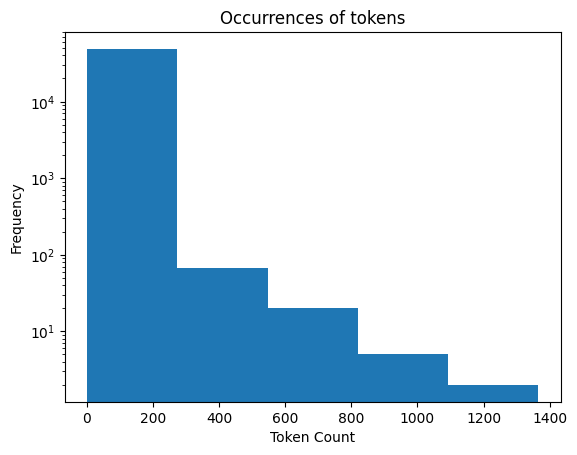

In [49]:
# TESTED AI CODE

# Load in packages
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# make hist
plt.hist(token_count.values(), bins=5)
#AI log code
plt.yscale('log')
#make title for hist
plt.title("Occurrences of tokens")
# make an xlabel for the hist
plt.xlabel("Token Count")
#make a ylabel for the hist
plt.ylabel("Frequency")
# show plot
plt.show()

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [50]:
# Your Phase 2 solution to the problem goes here.
#na same code from above

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The AI definitely helped me again in the sense of checking the accuracy of my plot and making sure I could fully interpret the data as well. Ultimately, the chat-bot did produce a few great suggestions that I was able to try and see which one was the best fit for scaling the x-axis to make the histogram better spatially. The log suggestion ended up being the best one. Once doing this test, it was apparent that my first assumption was right, and based off what the AI also responded, it seemed to just be a heavy right skew. Because of this, I decided to keep my original code due to it producing practically the same graph. One thing that the AI did wrong at first was give me options for my visualization code that included coding pieces that were not necessary, like edgecolor.






